# The granularity `alpha` against the range of the field

The argument `alpha` sets how fine the partitions are. Whether a given value is fine or coarse depends
on the field, on how far its correlation reaches. Here we compare the width of the cells with that
reach on a field whose truth we know, see what an ensemble does on either side of it, and let the
Pareto search choose.

## Learning goals

- How `alpha` sets the width of the cells, measured on the box of the data.
- Why partitions whose cells are wide against the range of the field impose their own structure,
  while narrow cells trace the field.
- Why more partitions do not repair cells that are too wide.
- How the Pareto search finds a granularity on the right side.

*How fine should the partitions be for this field?*

## The idea

Under the default Mondrian process, a cell has a typical width of about

$$w = \mu(D)\,(1 - \alpha),$$

with $\mu(D)$ the sum of the sides of the box of the data. The field has a range $a$, the distance
over which its values stay related. Two regimes follow from comparing the two lengths.

- With $w$ well above $a$ the cells are wide. Each cell mean averages places the field treats as
  unrelated, so the estimate reports a structure of its own, the partition's, and loses the contrast
  of the field.
- With $w$ well below $a$ the cells are narrow. Each cell holds places that move together, so the
  estimate follows the field.

On the unit square $\mu(D) = 2$, so a range of 0.3 asks for $w$ well below 0.3, that is, for `alpha`
well above 0.85. Finer is not better without limit, though, since narrow cells hold fewer data. The
Pareto search balances the two (see the tutorial on it). The theory Spatialize rests on derives both regimes in closed form for the cell-mean decoder ([Encoders](https://spatialize.readthedocs.io/en/latest/theory/encoders.html)).

## Step by step

### A field with a known range

The field is a Gaussian simulation on the unit square with an exponential covariance of scale 0.3,
computed on an 80 × 80 grid, with 1 500 of its nodes as data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.gs.esi import esi_griddata, esi_pareto_hparams_search
import spatialize.gs.esi.aggfunction as af
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen")

m, scale = 80, 0.3
grid = (np.arange(m) + 0.5) / m
nodes = np.stack(np.meshgrid(grid, grid, indexing="ij"), -1).reshape(-1, 2)
distance = np.sqrt(((nodes[:, None, :] - nodes[None, :, :]) ** 2).sum(-1))
rng = np.random.default_rng(11)
field = np.linalg.cholesky(np.exp(-distance / scale) + 1e-8 * np.eye(len(nodes))) @ rng.standard_normal(len(nodes))
picked = rng.choice(len(nodes), 1500, replace=False)
points, values, truth = nodes[picked], field[picked], field.reshape(m, m)
xi = np.stack(np.meshgrid(grid, grid, indexing="ij"))
box = np.ptp(points, axis=0).sum()
print(f"sum of the sides of the data box {box:.3f}")

sum of the sides of the data box 1.975


### The width of the cells

For each value of `alpha`, the width $w$ of a typical cell and its ratio to the range.

In [2]:
alphas = [0.7, 0.85, 0.9, 0.95, 0.985, 0.995]
widths = pd.DataFrame({"cell width": [box * (1 - a) for a in alphas]}, index=pd.Index(alphas, name="alpha"))
widths["width / range"] = widths["cell width"] / scale
widths.round(3)

,cell width,width / range
alpha,,
0.700,0.593,1.975
0.850,0.296,0.988
0.900,0.197,0.658
0.950,0.099,0.329
0.985,0.030,0.099
0.995,0.010,0.033


At `alpha` = 0.7 a cell is about twice as wide as the range, and at 0.985 about a tenth of it. These
two values sit clearly on either side, so we compare them.

### Two cell widths

The decoder is the cell mean, for which the theory's results are written, while the ensemble is read
through its median, which ignores a partition that splits a cell badly at a location. At the coarse
granularity we try 8 and 200 partitions.

In [3]:
runs = {"alpha 0.7, 8 partitions": (0.7, 8), "alpha 0.7, 200 partitions": (0.7, 200),
        "alpha 0.985, 200 partitions": (0.985, 200)}
estimates, rows = {}, {}
for name, (alpha, n) in runs.items():
    r = esi_griddata(points, values, xi, local_interpolator="cellmean", n_partitions=n, alpha=alpha, seed=0)
    estimate = r.re_estimate(af.median)
    estimates[name] = estimate
    rows[name] = {"RMSE": round(np.sqrt(np.mean((estimate - truth) ** 2)), 3),
                  "spread against the field's": round(estimate.std() / truth.std(), 2),
                  "correlation with the truth": round(np.corrcoef(estimate.ravel(), truth.ravel())[0, 1], 3)}
pd.DataFrame(rows).T

,RMSE,spread against the field's,correlation with the truth
"alpha 0.7, 8 partitions",0.759,0.29,0.606
"alpha 0.7, 200 partitions",0.773,0.22,0.650
"alpha 0.985, 200 partitions",0.253,0.90,0.960


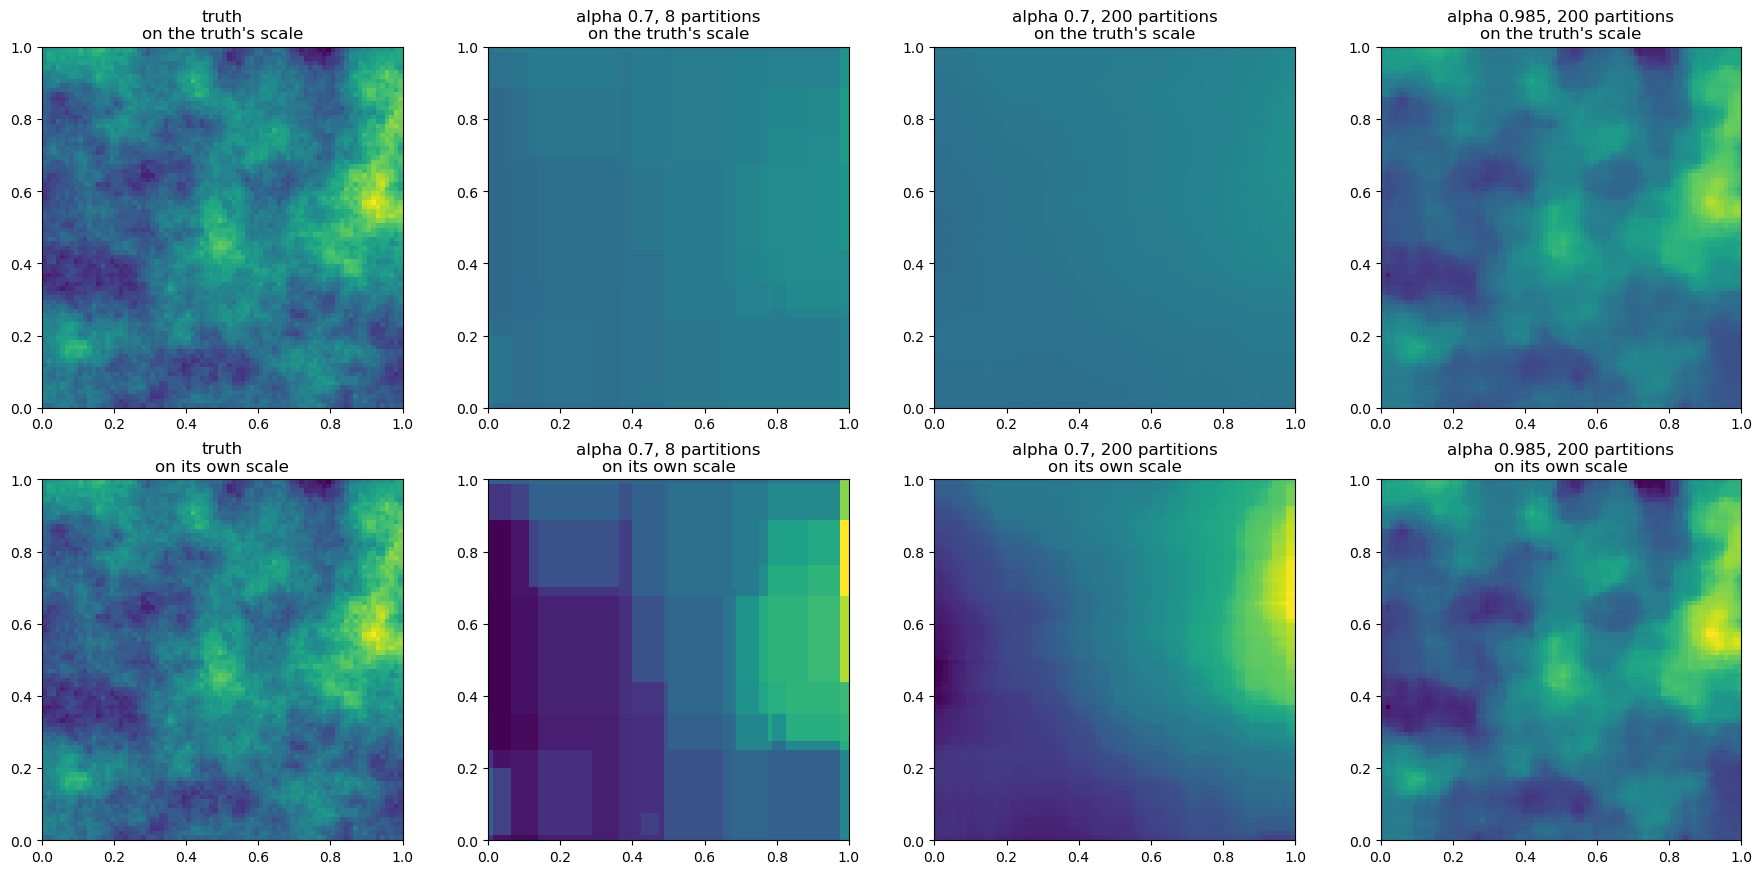

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.8))
for col, (name, f) in enumerate([("truth", truth)] + list(estimates.items())):
    axes[0, col].imshow(f.T, origin="lower", extent=(0, 1, 0, 1), cmap="viridis", vmin=truth.min(), vmax=truth.max())
    axes[0, col].set_title(f"{name}\non the truth's scale")
    axes[1, col].imshow(f.T, origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
    axes[1, col].set_title(f"{name}\non its own scale")
plt.tight_layout()
plt.show()

On the truth's scale (upper row) both coarse maps look almost flat, since they keep a third of the
field's spread or less. On their own scales (lower row), the map from 8 partitions at `alpha` = 0.7
shows axis-aligned blocks. With 200 partitions the blocks are gone and the correlation with the truth rises,
yet the error does not fall, while the spread shrinks further. On its own scale that map keeps only
the broad trend of the field, higher to the east, without any of its patches. More partitions average the blocks of
one partition against those of the next, which hides the symptom of cells too wide for the field and
leaves the bias in place. Narrowing the cells is the cure. At `alpha` = 0.985 the error drops to about
a third, with the spread back close to the field's and the map following the truth.

The correlation is a poor guide here, since it ignores the scale of the estimate. A smooth map that
has lost the amplitude of the field can correlate better than a blocky one while being no closer to
it.

### Letting the Pareto search choose

The range is rarely known, so in practice the granularity is chosen from the data. The Pareto search
compares the encoder error, which falls as the cells narrow, with the decoder error, which stops
falling once the cells hold too few data.

In [5]:
search = esi_pareto_hparams_search(points, values, local_interpolator="cellmean", n_partitions=[100],
                                   alpha=[0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 0.995], k=5, scoring=sf.mae, seed=0)
table = pd.DataFrame([{"alpha": r["params"]["alpha"], "encoder ε̂": r["epsilon"], "decoder error": r["decoder_error"]}
                      for r in search.all_results]).set_index("alpha").sort_index()
knee = search.best_result(strategy="knee")["alpha"]
table["cell width / range"] = box * (1 - table.index) / scale
print(f"alpha at the knee {knee}, a cell {box * (1 - knee) / scale:.2f} of the range wide")
table.round(4)

alpha at the knee 0.995, a cell 0.03 of the range wide


,encoder ε̂,decoder error,cell width / range
alpha,,,
0.700,420.2851,0.6092,1.9750
0.800,344.6685,0.5672,1.3167
0.900,207.5722,0.4635,0.6583
0.950,113.7264,0.3522,0.3292
0.980,44.0021,0.2471,0.1317
0.990,14.5694,0.2179,0.0658
0.995,3.3505,0.2136,0.0329


The decoder error falls quickly while the cells narrow below the range, then almost stops falling past
`alpha` = 0.99, while the encoder error keeps falling. Over this grid both errors fall all the way, so
the finest value beats every other on both counts, which reduces the frontier to it. Finer values would
gain little in decoder error and cost far more to compute. The choice lands where the cells are a small
fraction of the range, on the side where the estimate traces the field, without the search knowing the
range.

## Pitfalls

- **A smooth map taken for a good one.** More partitions at a coarse granularity give a clean map with
  the same error and less contrast. Judge the granularity by the error and the spread, not by how
  clean the map looks.
- **The same `alpha` on other data.** The width of the cells is measured on the box of the data, so the
  same value gives wide cells on a large domain and narrow ones on a small one. Think of `alpha`
  through the width $\mu(D)(1 - \alpha)$.
- **Very fine partitions.** The number of cells grows like $1/(1-\alpha)^d$ in $d$ dimensions, so very
  fine values cost time and memory, while each cell holds fewer data. Search a grid that stops once the
  decoder error flattens.
- **The range unknown.** It usually is, which is why the Pareto search chooses `alpha` from the data.

## Try it yourself

1. Change `scale` to 0.1 and to 0.6 and see how the regimes and the knee move.
2. Draw 3 000 data instead of 1 500 at `alpha` = 0.7. The structure the partition imposes fades as the
   cells fill with data, while a structure the field carries would stay.
3. Repeat the comparison with the adaptive IDW (`local_interpolator="adaptiveidw"`), which fits a
   direction inside each cell.

## Next

- *Encoders, Mondrian or Voronoi*, for the partitions whose cells are measured here.
- *Choosing an ensemble with the Pareto search*, for the search used to choose `alpha`.
- *How many partitions?*, for what more partitions do and do not do.
- *Cells without data*, for the empty cells fine partitions leave.
- The documentation's [Encoders](https://spatialize.readthedocs.io/en/latest/theory/encoders.html) (theory).